In [ ]:
!pip install imagecodecs # restart runtime after installation

In [1]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tifffile as tiff
import cv2

import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve

# Verify GPU Availability in Kaggle
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU Available: {gpus[0].name}")
else:
    print("WARNING: No GPU detected. Make sure GPU accelerator is enabled in Kaggle settings.")

GPU Available: /physical_device:GPU:0


In [2]:
# Hardcoded paths matching your dataset directory structure on Kaggle
PATHS = {
    "RGB_HEALTHY": "/kaggle/input/datasets/amrutdesh/weedyrice-dataset/weedyrice-square/healthy-square",
    "RGB_UNHEALTHY": "/kaggle/input/datasets/amrutdesh/weedyrice-dataset/weedyrice-square/weedy-square",
    
    "MS_HEALTHY_R": "/kaggle/input/datasets/amrutdesh/weedyrice-healthy-mps/healthy/R",
    "MS_HEALTHY_G": "/kaggle/input/datasets/amrutdesh/weedyrice-healthy-mps/healthy/G",
    "MS_HEALTHY_NIR": "/kaggle/input/datasets/amrutdesh/weedyrice-healthy-mps/healthy/NIR",
    
    "MS_UNHEALTHY_R": "/kaggle/input/datasets/amrutdesh/weedyrice-unhealthy-mps/unhealthy/R",
    "MS_UNHEALTHY_G": "/kaggle/input/datasets/amrutdesh/weedyrice-unhealthy-mps/unhealthy/G",
    "MS_UNHEALTHY_NIR": "/kaggle/input/datasets/amrutdesh/weedyrice-unhealthy-mps/unhealthy/NIR",
}

In [16]:
def load_and_stack_multispectral(r_path, g_path, nir_path):
    r_path = r_path.numpy().decode('utf-8')
    g_path = g_path.numpy().decode('utf-8')
    nir_path = nir_path.numpy().decode('utf-8')

    # cv2.IMREAD_UNCHANGED retains native 16-bit or float32 bit depth
    r = cv2.imread(r_path, cv2.IMREAD_UNCHANGED)
    g = cv2.imread(g_path, cv2.IMREAD_UNCHANGED)
    nir = cv2.imread(nir_path, cv2.IMREAD_UNCHANGED)

    if r is None or g is None or nir is None:
        raise FileNotFoundError("One or more TIFF channels could not be read by OpenCV.")

    r = r.astype(np.float32)
    g = g.astype(np.float32)
    nir = nir.astype(np.float32)

    # Normalize bit depth dynamically
    max_val = max(r.max(), g.max(), nir.max())
    if max_val > 0:
        r, g, nir = r / max_val, g / max_val, nir / max_val

    # Stack into [NIR, Red, Green] -> shape: (H, W, 3)
    stacked = np.stack([nir, r, g], axis=-1)
    return stacked.astype(np.float32)

def process_ms_sample(r_path, g_path, nir_path, label):
    img = tf.py_function(
        func=load_and_stack_multispectral,
        inp=[r_path, g_path, nir_path],
        Tout=tf.float32
    )
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, [260, 260])
    return img, label

def process_rgb_sample(jpg_path, label):
    raw = tf.io.read_file(jpg_path)
    # decode_image handles JPEG, PNG, and BMP safely
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)
    img = tf.image.convert_image_dtype(img, tf.float32)
    img = tf.image.resize(img, [260, 260])
    return img, label

def build_data_pipeline(paths_dict, batch_size=16, max_samples_per_folder=100):
    r_paths, g_paths, nir_paths, ms_labels = [], [], [], []
    jpg_paths, rgb_labels = [], []

    def glob_images(folder_path, exts=("*.jpg", "*.jpeg", "*.png", "*.JPG", "*.PNG")):
        files = []
        for ext in exts:
            files.extend(glob.glob(os.path.join(folder_path, ext)))
        return sorted(files)

    def match_ms_triplets(r_dir, g_dir, nir_dir, label, max_samples):
        # Find all Red files in the Red folder
        r_files = glob_images(r_dir, exts=("*.tif", "*.TIF", "*.tiff", "*.TIFF"))
        
        valid_r, valid_g, valid_nir, valid_labels = [], [], [], []
        
        for r_file in r_files:
            fname = os.path.basename(r_file)
            
            # Robustly swap suffix naming (_R.tif -> _G.tif / _NIR.tif)
            if "_R." in fname:
                g_fname = fname.replace("_R.", "_G.")
                nir_fname = fname.replace("_R.", "_NIR.")
            elif "_red." in fname:
                g_fname = fname.replace("_red.", "_green.")
                nir_fname = fname.replace("_red.", "_nir.")
            else:
                # Direct fallback if filenames are identical across folders
                g_fname = fname
                nir_fname = fname
                
            g_file = os.path.join(g_dir, g_fname)
            nir_file = os.path.join(nir_dir, nir_fname)

            # Only append if corresponding G and NIR files exist on disk
            if os.path.exists(g_file) and os.path.exists(nir_file):
                valid_r.append(r_file)
                valid_g.append(g_file)
                valid_nir.append(nir_file)
                valid_labels.append(label)

                # Stop early if max_samples_per_folder threshold is reached
                if max_samples is not None and len(valid_r) >= max_samples:
                    break

        return valid_r, valid_g, valid_nir, valid_labels

    # 1. Map Multispectral Healthy (Label = 0)
    r_h, g_h, nir_h, lbl_h = match_ms_triplets(
        paths_dict["MS_HEALTHY_R"],
        paths_dict["MS_HEALTHY_G"],
        paths_dict["MS_HEALTHY_NIR"],
        label=0,
        max_samples=max_samples_per_folder
    )
    r_paths.extend(r_h); g_paths.extend(g_h); nir_paths.extend(nir_h); ms_labels.extend(lbl_h)

    # 2. Map Multispectral Unhealthy (Label = 1)
    r_u, g_u, nir_u, lbl_u = match_ms_triplets(
        paths_dict["MS_UNHEALTHY_R"],
        paths_dict["MS_UNHEALTHY_G"],
        paths_dict["MS_UNHEALTHY_NIR"],
        label=1,
        max_samples=max_samples_per_folder
    )
    r_paths.extend(r_u); g_paths.extend(g_u); nir_paths.extend(nir_u); ms_labels.extend(lbl_u)

    # 3. Map RGB Healthy (Label = 0)
    rgb_healthy_files = glob_images(paths_dict["RGB_HEALTHY"])
    if max_samples_per_folder is not None:
        rgb_healthy_files = rgb_healthy_files[:max_samples_per_folder]

    for img_path in rgb_healthy_files:
        jpg_paths.append(img_path)
        rgb_labels.append(0)

    # 4. Map RGB Unhealthy (Label = 1)
    rgb_unhealthy_files = glob_images(paths_dict["RGB_UNHEALTHY"])
    if max_samples_per_folder is not None:
        rgb_unhealthy_files = rgb_unhealthy_files[:max_samples_per_folder]

    for img_path in rgb_unhealthy_files:
        jpg_paths.append(img_path)
        rgb_labels.append(1)

    total_samples = len(r_paths) + len(jpg_paths)
    print(f"Loaded {len(r_paths)} Multispectral triplets and {len(jpg_paths)} RGB images (Total: {total_samples}).")

    if total_samples == 0:
        raise ValueError("No images found! Please check path configurations in `paths_dict`.")

    # Build Streams
    ds_list = []

    if len(r_paths) > 0:
        ds_ms = tf.data.Dataset.from_tensor_slices((r_paths, g_paths, nir_paths, ms_labels))
        ds_ms = ds_ms.map(process_ms_sample, num_parallel_calls=tf.data.AUTOTUNE)
        ds_list.append(ds_ms)

    if len(jpg_paths) > 0:
        ds_rgb = tf.data.Dataset.from_tensor_slices((jpg_paths, rgb_labels))
        ds_rgb = ds_rgb.map(process_rgb_sample, num_parallel_calls=tf.data.AUTOTUNE)
        ds_list.append(ds_rgb)

    base_ds = ds_list[0].concatenate(ds_list[1]) if len(ds_list) == 2 else ds_list[0]

    # Training Pipeline (Shuffled & Batched)
    train_ds = base_ds.shuffle(buffer_size=total_samples)
    train_ds = train_ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

    # Evaluation Pipeline (Sequential & Batched)
    eval_ds = base_ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

    return train_ds, eval_ds, total_samples

# Execution with sample limit per folder (e.g., limit to 50 images per category during rapid prototyping)
MAX_PER_FOLDER = 500  # Set to None when training on the full dataset!

train_dataset, eval_dataset, total_samples = build_data_pipeline(
    PATHS, 
    batch_size=16, 
    max_samples_per_folder=MAX_PER_FOLDER
)

Loaded 1000 Multispectral triplets and 1000 RGB images (Total: 2000).


In [17]:
def build_model(input_shape=(260, 260, 3), num_classes=2):
    base_model = tf.keras.applications.EfficientNetB2(
        include_top=False,
        weights='imagenet',
        input_shape=input_shape
    )

    # Partial Fine-Tuning: Unfreeze the last 30 layers
    base_model.trainable = True
    for layer in base_model.layers[:-30]:
        layer.trainable = False

    inputs = tf.keras.Input(shape=input_shape)
    x = layers.RandomFlip("horizontal_and_vertical")(inputs)
    x = layers.RandomRotation(0.2)(x)
    x = base_model(x, training=True)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs, name="EfficientNetB0_Agro_Health")
    return model

model = build_model()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Save model directly in modern Keras v3 native .keras format
KERAS_MODEL_PATH = "rice_health_efficientnet_500-25.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(KERAS_MODEL_PATH, save_best_only=True, monitor="loss"),
    tf.keras.callbacks.EarlyStopping(monitor="loss", patience=3, restore_best_weights=True)
]

print("Training Model...")
history = model.fit(
    train_dataset,
    epochs=25,
    callbacks=callbacks
)

31790344/31790344 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Model...
Epoch 1/25


E0000 00:00:1790227092.138392     278 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_Agro_Health_1/efficientnetb2_1/block1b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


125/125 ━━━━━━━━━━━━━━━━━━━━ 36s 110ms/step - accuracy: 0.4665 - loss: 0.7379
Epoch 2/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - accuracy: 0.5180 - loss: 0.7097
Epoch 3/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 18s 105ms/step - accuracy: 0.5080 - loss: 0.7073
Epoch 4/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 18s 106ms/step - accuracy: 0.5255 - loss: 0.7007
Epoch 5/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 98ms/step - accuracy: 0.5155 - loss: 0.7021
Epoch 6/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 108ms/step - accuracy: 0.5240 - loss: 0.6958
Epoch 7/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 18s 105ms/step - accuracy: 0.5460 - loss: 0.6945
Epoch 8/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 96ms/step - accuracy: 0.5315 - loss: 0.6992
Epoch 9/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 18s 108ms/step - accuracy: 0.5610 - loss: 0.6883
Epoch 10/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 98ms/step - accuracy: 0.5370 - loss: 0.6915
Epoch 11/25
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 111ms/step - accuracy: 0.5405 - loss: 0.6881
Epoch 12/25
125/125 ━━━━━━━━━━━━━

In [18]:
# Option 1: Predict directly on the batched evaluation dataset
y_pred_probs = model.predict(eval_dataset, verbose=1)

# Option 2: Compute loss and evaluation metrics in one call
loss, accuracy = model.evaluate(eval_dataset, verbose=1)
print(f"Evaluation Accuracy: {accuracy * 100:.2f}%")

125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 95ms/step
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 97ms/step - accuracy: 0.5135 - loss: 0.9079
Evaluation Accuracy: 51.35%


125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 94ms/step
y_true shape: (2000,), y_pred shape: (2000,)

--- Classification Report ---
              precision    recall  f1-score   support

     Healthy       0.86      0.03      0.06      1000
   Unhealthy       0.51      0.99      0.67      1000

    accuracy                           0.51      2000
   macro avg       0.69      0.51      0.37      2000
weighted avg       0.69      0.51      0.37      2000



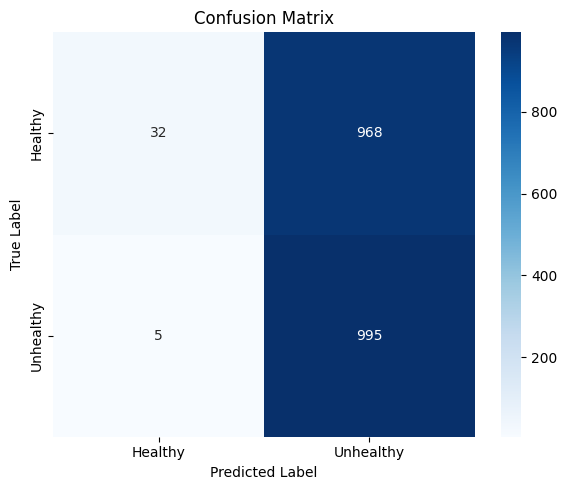

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Predict raw probabilities from model
preds = model.predict(eval_dataset, verbose=1)  # Expected shape: (200, 2)

# If predictions are 2D (softmax with 2 units), take argmax across classes
if preds.ndim > 1 and preds.shape[1] == 2:
    y_pred = np.argmax(preds, axis=1)
# If predictions are 1D or (N, 1) sigmoid output, threshold at 0.5
else:
    y_pred = (preds.ravel() >= 0.5).astype(int)

# 2. Extract true ground-truth labels sequentially
y_true = []
for _, labels in eval_dataset:
    y_true.extend(labels.numpy())

y_true = np.array(y_true)

# Verify matching shape alignment
print(f"y_true shape: {y_true.shape}, y_pred shape: {y_pred.shape}")

# 3. Print Classification Report
class_names = ["Healthy", "Unhealthy"]
print("\n--- Classification Report ---")
print(classification_report(y_true, y_pred, target_names=class_names))

# 4. Generate and Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()